# GDP per Capita, Jobs and Health, 2000-2024: An Exploratory Data Analysis

**Course:** 04-638 Programming for Data Analytics | **Instructor:** Dr. George Onyango Okeyo
**Assignment:** Analytics Assignment I: Exploratory Data Analysis and Reporting | **Group 2**
**Members:** Aristide Isingizwe, Christine Akoto-Nimoh, Venus Kanobayita Uwera | **Submission date:** 30 October 2026

**Assigned dataset:** GDP per capita (current US$), World Bank World Development Indicators (WDI).
**Supporting indicators:** Unemployment, total (% of labour force, national estimate) and Life expectancy at birth, total (years).

**How this notebook is organised**

1. Preliminary questions and supporting indicators
2. Setup
3. A first look at the raw file
4. Loading, cleaning and merging the data
5. Exploratory data analysis
    - 5a. Understanding the data
    - 5b. Basic statistics and distributions
    - 5c. Visualisations
    - 5d. Missing values and outliers
    - 5e. Trends, patterns and relationships
    - 5f. Answers to the eight questions
6. Summary and limitations

> Everything in this notebook is an **association** found by exploring the data. None of it proves that one thing causes another.

## 1. Preliminary questions and supporting indicators

After a first look at the data we wrote down twelve questions. The eight marked ✅ are answered in Section 5f. Questions 1, 2, 3, 7, 8 and 9 use GDP per capita **together with** at least one supporting indicator.

| # | Question | Answered |
|---|----------|:---:|
| 1 | How are GDP per capita, unemployment and life expectancy related across countries from 2000 to 2024? | ✅ |
| 2 | Do countries with higher GDP per capita tend to have lower unemployment rates? | ✅ |
| 3 | Do countries with higher GDP per capita tend to have longer life expectancy? | ✅ |
| 4 | Within each country, how do changes in GDP per capita relate to changes in unemployment? | |
| 5 | Within each country, how do changes in GDP per capita relate to changes in life expectancy? | |
| 6 | How is unemployment related to life expectancy? | |
| 7 | Which countries have high GDP per capita but also high unemployment? | ✅ |
| 8 | Which countries have low GDP per capita but relatively high life expectancy? | ✅ |
| 9 | Did these relationships differ between 2000-2019 and 2020-2024? | ✅ |
| 10 | How do the three indicators differ across continents? | ✅ |
| 11 | Is the GDP-life expectancy relationship stronger in some continents than others? | |
| 12 | Which continent saw the largest life expectancy gain, and how did GDP per capita change over the same period? | ✅ |

**Why these two supporting indicators?**

| Indicator | Why we chose it | Coverage check |
|---|---|---|
| Life expectancy at birth, total (years) | Richer countries can usually spend more on health care, food and clean water, so we expect higher GDP per capita to go with longer lives. | Available for every country and every year (100%). |
| Unemployment, total (% of labour force, national estimate) | Shows how well an economy provides jobs. We want to see whether richer countries also have fewer people out of work. | About 59% of country-years. Some countries do not report it every year, so results that use it rest on fewer countries. |

## 2. Setup

We use the basic toolkit (numpy, pandas, matplotlib) plus seaborn for a few charts. The folder `figures/` is where we save the charts used in the report.

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
sns.set_theme(style="whitegrid")
os.makedirs("figures", exist_ok=True)   # charts for the report are saved here

## 3. A first look at the raw file

The World Bank lets you download several indicators in one CSV. Our file `data/All_three_combined.csv` holds all three indicators. Before cleaning anything, we look at its size, first rows and last rows.

In [3]:
DATA_FILE = "data/All_three_combined.csv"

raw = pd.read_csv(DATA_FILE)
print("Rows and columns:", raw.shape)
raw.head()

Rows and columns: (798, 29)


,Country Name,Country Code,Series Name,Series Code,2000 [YR2000],2001 [YR2001],2002 [YR2002],2003 [YR2003],2004 [YR2004],2005 [YR2005],...,2015 [YR2015],2016 [YR2016],2017 [YR2017],2018 [YR2018],2019 [YR2019],2020 [YR2020],2021 [YR2021],2022 [YR2022],2023 [YR2023],2024 [YR2024]
0,Afghanistan,AFG,GDP per capita (current US$),NY.GDP.PCAP.CD,174.930991430166,138.706821676113,178.954088379235,198.871115728727,221.763653873013,254.184249149336,...,565.569730408751,522.082215583898,525.469770891619,491.337221382603,496.6025042585,510.787063366811,356.496214115892,357.261152798144,413.757894705303,416.871146273728
1,Afghanistan,AFG,"Life expectancy at birth, total (years)",SP.DYN.LE00.IN,55.005,55.511,56.225,57.171,57.81,58.247,...,62.27,62.646,62.406,62.443,62.941,61.454,60.417,65.617,66.035,66.289
2,Afghanistan,AFG,"Unemployment, total (% of total labor force) (...",SL.UEM.TOTL.NE.ZS,..,..,..,..,..,..,...,..,..,11.184,..,..,11.71,5.679,..,..,..
3,Albania,ALB,GDP per capita (current US$),NY.GDP.PCAP.CD,1160.42047054038,1326.41652388077,1479.83884572006,1908.69900687608,2446.90949947798,2741.72136549578,...,4199.53912925398,4457.63412207495,5006.36012951959,5897.65452588774,6069.43903131027,6027.91350716348,7242.45513146613,7756.96188744253,9740.7023414631,11374.0085781236
4,Albania,ALB,"Life expectancy at birth, total (years)",SP.DYN.LE00.IN,74.826,75.083,75.299,75.557,75.951,76.427,...,78.358,78.643,78.9,79.238,79.467,77.824,76.844,78.769,79.602,79.776


In [4]:
raw.tail()

,Country Name,Country Code,Series Name,Series Code,2000 [YR2000],2001 [YR2001],2002 [YR2002],2003 [YR2003],2004 [YR2004],2005 [YR2005],...,2015 [YR2015],2016 [YR2016],2017 [YR2017],2018 [YR2018],2019 [YR2019],2020 [YR2020],2021 [YR2021],2022 [YR2022],2023 [YR2023],2024 [YR2024]
793,Upper middle income,UMC,"Life expectancy at birth, total (years)",SP.DYN.LE00.IN,70.7453581446278,71.0574540062592,71.3497029374728,71.5890770162384,71.6980637522242,72.2010061107617,...,74.934843438781,75.0906548982392,75.2402306964393,75.5511819443353,75.7442027654668,75.0593316548277,74.4180568484505,75.7285192648647,75.9179864449912,76.0451247995029
794,Upper middle income,UMC,"Unemployment, total (% of total labor force) (...",SL.UEM.TOTL.NE.ZS,5.50523954642366,4.40985417329795,4.88276257682656,4.40443012979498,4.25436765625608,4.65634286324357,...,4.70606455609453,5.30595054743556,5.36885230463362,5.84867963143957,5.98569778783382,6.65226371002623,6.36410975213873,5.36714182295411,..,..
795,World,WLD,GDP per capita (current US$),NY.GDP.PCAP.CD,5512.56177163867,5404.20269822848,5539.32465002692,6129.8663827398,6818.00375324835,7290.5661453297,...,10191.9752512663,10239.4656645738,10784.3950896297,11344.728168656,11417.5958587724,10999.4917581781,12472.9074157191,12876.2377124072,13313.8575826001,13717.0909956338
796,World,WLD,"Life expectancy at birth, total (years)",SP.DYN.LE00.IN,67.650477873849,67.9451852910729,68.2313680755001,68.5157832704694,68.7710985282212,69.111445965915,...,71.9656376386893,72.1858228976021,72.3662967648278,72.6442408544831,72.869911203356,72.1832040176208,71.2160780260296,72.9689585478052,73.3302230276375,73.4818184164654
797,World,WLD,"Unemployment, total (% of total labor force) (...",SL.UEM.TOTL.NE.ZS,5.46474199941114,5.37082217114415,..,5.54133870200259,..,5.21488599084366,...,5.29007572529697,5.53894606131214,5.57477237475399,5.96482876493804,5.69736051304206,6.72819858552599,6.19336938600857,5.08409139190666,..,..


**What we notice**

- The file is in the World Bank "wide" layout: **one row per country and indicator**, and **one column per year** (`2000 [YR2000]` ... `2024 [YR2024]`).
- Missing values are written as `..` instead of being left empty, so pandas reads the year columns as text.
- Besides real countries, the file has **regional and income-group totals** such as "World" or "Euro area". If we kept them, some countries would be counted twice.
- Downloaded World Bank files can end with a few note lines ("Data from database...", "Last Updated...") that are not data.

## 4. Loading, cleaning and merging the data

We clean the data in five small steps.

**Step 1: read the file properly.** `na_values=".."` turns the `..` marks into real missing values (NaN). Rows with no `Series Code` are the note lines at the bottom, so we drop them.

In [5]:
data = pd.read_csv(DATA_FILE, na_values="..")
data = data.dropna(subset=["Series Code"])

print("Rows after removing note lines:", len(data))
print("Indicators in the file:")
print(data["Series Name"].value_counts())

Rows after removing note lines: 798
Indicators in the file:
Series Name
GDP per capita (current US$)                                        266
Life expectancy at birth, total (years)                             266
Unemployment, total (% of total labor force) (national estimate)    266
Name: count, dtype: int64


**Step 2: reshape from wide to long, then to one row per country and year.**

`melt` turns the 25 year columns into two columns (`year` and `value`). `pivot` then puts each indicator in its own column. The result has one row per country-year and one column per indicator, which is much easier to analyse.

In [6]:
year_columns = [col for col in data.columns if "[YR" in col]

long = data.melt(
    id_vars=["Country Name", "Country Code", "Series Code"],
    value_vars=year_columns,
    var_name="year",
    value_name="value",
)

long["year"] = long["year"].str[:4].astype(int)  # "2000 [YR2000]" -> 2000

short_names = {
    "NY.GDP.PCAP.CD": "gdp_per_capita",
    "SL.UEM.TOTL.NE.ZS": "unemployment_rate",
    "SP.DYN.LE00.IN": "life_expectancy",
}
long["indicator"] = long["Series Code"].map(short_names)

df = long.pivot(
    index=["Country Name", "Country Code", "year"], columns="indicator", values="value"
).reset_index()
df.columns.name = None
df.head()

,Country Name,Country Code,year,gdp_per_capita,life_expectancy,unemployment_rate
0,Afghanistan,AFG,2000,174.930991,55.005,NaN
1,Afghanistan,AFG,2001,138.706822,55.511,NaN
2,Afghanistan,AFG,2002,178.954088,56.225,NaN
3,Afghanistan,AFG,2003,198.871116,57.171,NaN
4,Afghanistan,AFG,2004,221.763654,57.810,NaN


**Step 3: remove regional and income-group totals.** These rows use special World Bank codes (for example `WLD` = World, `SSF` = Sub-Saharan Africa). We list the codes and keep everything else.

In [7]:
aggregate_codes = [
    "AFE",
    "AFW",
    "ARB",
    "CEB",
    "CSS",
    "EAP",
    "EAR",
    "EAS",
    "ECA",
    "ECS",
    "EMU",
    "EUU",
    "FCS",
    "FCV",
    "HIC",
    "HPC",
    "IBD",
    "IBT",
    "IDA",
    "IDB",
    "IDX",
    "INX",
    "LAC",
    "LCN",
    "LDC",
    "LIC",
    "LMC",
    "LMY",
    "LTE",
    "MEA",
    "MIC",
    "MNA",
    "NAC",
    "OED",
    "OSS",
    "PRE",
    "PSS",
    "PST",
    "SAS",
    "SSA",
    "SSF",
    "SST",
    "TEA",
    "TEC",
    "TLA",
    "TMN",
    "TSA",
    "TSS",
    "UMC",
    "WLD",
]

print("Entities before:", df["Country Code"].nunique())
df = df[~df["Country Code"].isin(aggregate_codes)].copy()
print("Countries after removing totals:", df["Country Code"].nunique())

Entities before: 266
Countries after removing totals: 217


**Step 4: add a continent column.** The file has no region column, so we assign each country to a continent using its 3-letter code. Middle Eastern countries are counted in Asia; Central America and the Caribbean are counted in North America.

In [8]:
continent_codes = {
    "Africa": "DZA AGO BEN BWA BFA BDI CPV CMR CAF TCD COM COD COG CIV DJI EGY GNQ ERI SWZ ETH GAB GMB "
    "GHA GIN GNB KEN LSO LBR LBY MDG MWI MLI MRT MUS MAR MOZ NAM NER NGA RWA STP SEN SYC SLE "
    "SOM ZAF SSD SDN TZA TGO TUN UGA ZMB ZWE",
    "Asia": "AFG ARM AZE BHR BGD BTN BRN KHM CHN GEO HKG IND IDN IRN IRQ ISR JPN JOR KAZ KWT KGZ LAO LBN "
    "MAC MYS MDV MNG MMR NPL PRK OMN PAK PSE PHL QAT SAU SGP KOR LKA SYR TJK THA TLS TUR TKM ARE "
    "UZB VNM YEM",
    "Europe": "ALB AND AUT BLR BEL BIH BGR HRV CYP CZE DNK EST FRO FIN FRA DEU GIB GRC HUN ISL IRL IMN ITA "
    "XKX LVA LIE LTU LUX MLT MDA MCO MNE NLD MKD NOR POL PRT ROU RUS SMR SRB SVK SVN ESP SWE "
    "CHE UKR GBR CHI",
    "North America": "ATG BHS BRB BLZ BMU CAN CYM CRI CUB CUW DMA DOM SLV GRL GRD GTM HTI HND JAM MEX NIC "
    "PAN PRI KNA LCA MAF VCT SXM TTO TCA USA VGB VIR ABW",
    "South America": "ARG BOL BRA CHL COL ECU GUY PRY PER SUR URY VEN",
    "Oceania": "ASM AUS FJI PYF GUM KIR MHL FSM NRU NCL NZL MNP PLW PNG WSM SLB TON TUV VUT",
}

code_to_continent = {}
for continent, codes in continent_codes.items():
    for c in codes.split():
        code_to_continent[c] = continent

df["continent"] = df["Country Code"].map(code_to_continent)

print(
    "Countries without a continent:",
    df.loc[df["continent"].isna(), "Country Name"].unique(),
)
print(df.drop_duplicates("Country Name")["continent"].value_counts())

Countries without a continent: <StringArray>
[]
Length: 0, dtype: str
continent
Africa           54
Asia             49
Europe           49
North America    34
Oceania          19
South America    12
Name: count, dtype: int64


**Step 5: build a country summary table.** Many questions compare countries, so we average each country's values over 2000-2024. To avoid an average built from only one or two years, a country needs **at least 5 years of data** for an indicator; otherwise its average is left missing.

In [9]:
country_avg = (
    df.groupby(["Country Name", "continent"])
    .agg(
        gdp_per_capita=("gdp_per_capita", "mean"),
        unemployment_rate=("unemployment_rate", "mean"),
        life_expectancy=("life_expectancy", "mean"),
        gdp_years=("gdp_per_capita", "count"),
        unemployment_years=("unemployment_rate", "count"),
    )
    .reset_index()
)

country_avg.loc[country_avg["gdp_years"] < 5, "gdp_per_capita"] = np.nan
country_avg.loc[country_avg["unemployment_years"] < 5, "unemployment_rate"] = np.nan

country_avg.head()

,Country Name,continent,gdp_per_capita,unemployment_rate,life_expectancy,gdp_years,unemployment_years
0,Afghanistan,Asia,415.549994,6.779000,60.72348,25,6
1,Albania,Europe,4663.278818,13.078960,77.71324,25,25
2,Algeria,Africa,4272.813860,15.089778,74.07512,25,18
3,American Samoa,Oceania,11575.375660,NaN,72.40756,21,3
4,Andorra,Europe,40413.028948,NaN,83.49940,25,0


## 5. Exploratory data analysis

### 5a. Understanding the data: attributes, types and size

In [10]:
print("Rows (country-years):", len(df))
print("Countries:", df["Country Name"].nunique())
print("Years:", df["year"].min(), "to", df["year"].max())
print()
df.info()

Rows (country-years): 5425
Countries: 217
Years: 2000 to 2024

<class 'pandas.DataFrame'>
Index: 5425 entries, 0 to 6649
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Country Name       5425 non-null   str    
 1   Country Code       5425 non-null   str    
 2   year               5425 non-null   int64  
 3   gdp_per_capita     5242 non-null   float64
 4   life_expectancy    5425 non-null   float64
 5   unemployment_rate  3177 non-null   float64
 6   continent          5425 non-null   str    
dtypes: float64(3), int64(1), str(3)
memory usage: 339.1 KB


**Data dictionary**

| Column | Type | Role | Meaning |
|---|---|---|---|
| `Country Name` | text | identifier | Country or territory name |
| `Country Code` | text | identifier | World Bank 3-letter code |
| `year` | integer | time | 2000 to 2024 |
| `gdp_per_capita` | number | **main indicator** | GDP per person in current US dollars (not adjusted for inflation or local prices) |
| `unemployment_rate` | number | supporting | % of the labour force without work (each country's own definition) |
| `life_expectancy` | number | supporting | Years a newborn is expected to live |
| `continent` | text | added by us | Continent of the country |

**What 5a shows**

- After cleaning we have **217 countries x 25 years = 5,425 rows**, with three numeric indicators.
- **Life expectancy is complete (100%)**, GDP per capita is almost complete (about 97%), and **unemployment is the weakest field (about 59%)**.
- The most important fields are `gdp_per_capita` (our main indicator), `year` (for trends), `continent` (for regional comparisons) and the two supporting indicators.

### 5b. Basic statistics and distributions

In [11]:
indicators = ["gdp_per_capita", "unemployment_rate", "life_expectancy"]

stats_table = df[indicators].describe().T
stats_table["skew"] = df[indicators].skew()
stats_table.round(2)

,count,mean,std,min,25%,50%,75%,max,skew
gdp_per_capita,5242.0,16314.53,25475.38,109.59,1576.38,5464.72,21289.68,288001.57,3.32
unemployment_rate,3177.0,8.05,6.35,0.00,3.94,6.37,10.15,57.00,2.16
life_expectancy,5425.0,71.02,8.75,14.66,65.55,72.66,77.57,86.50,-0.83


`skew` tells us whether a distribution is lopsided: a positive value means a long tail of high values, a negative value a long tail of low values.

GDP per capita has a very long right tail (a few very rich countries), so we plot it on a **log scale**, where each step on the axis is ten times bigger than the last. This makes the spread of poorer and middle-income countries visible.

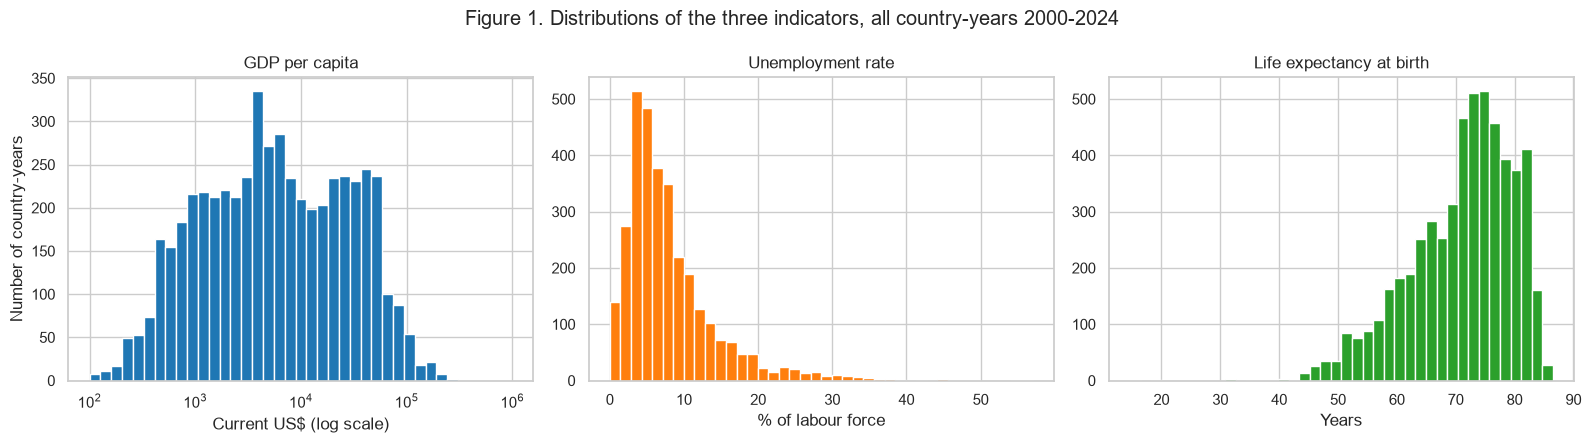

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

gdp = df["gdp_per_capita"].dropna()
axes[0].hist(gdp, bins=np.logspace(2, 6, 40), color="tab:blue", edgecolor="white")
axes[0].set_xscale("log")
axes[0].set_title("GDP per capita")
axes[0].set_xlabel("Current US$ (log scale)")
axes[0].set_ylabel("Number of country-years")

axes[1].hist(
    df["unemployment_rate"].dropna(), bins=40, color="tab:orange", edgecolor="white"
)
axes[1].set_title("Unemployment rate")
axes[1].set_xlabel("% of labour force")

axes[2].hist(
    df["life_expectancy"].dropna(), bins=40, color="tab:green", edgecolor="white"
)
axes[2].set_title("Life expectancy at birth")
axes[2].set_xlabel("Years")

fig.suptitle(
    "Figure 1. Distributions of the three indicators, all country-years 2000-2024"
)
plt.tight_layout()
plt.savefig("figures/fig1_distributions.png", dpi=200, bbox_inches="tight")
plt.show()

**What 5b shows**

- **GDP per capita is extremely uneven.** The median is about \$5,500 but the mean is about \$16,300, three times higher, because a few small rich economies (Monaco, Liechtenstein, Bermuda) reach \$140,000-\$290,000. Skew is about 3.3. On a log scale the distribution looks much more balanced.
- **Unemployment is also right-skewed** (skew about 2.2): the median is about 6.4% and the mean 8.1%, with a few very high values (Kosovo reached 57%).
- **Life expectancy is left-skewed** (skew about -0.8): most country-years sit between 65 and 80 years (median 72.7), with a tail of low values from countries hit by HIV/AIDS, conflict or disasters.

### 5c. Visualisations

**Trends over time.** For each year we take the **median** country, which is not pulled around by a few extreme countries. Each indicator gets its own chart because their units differ.

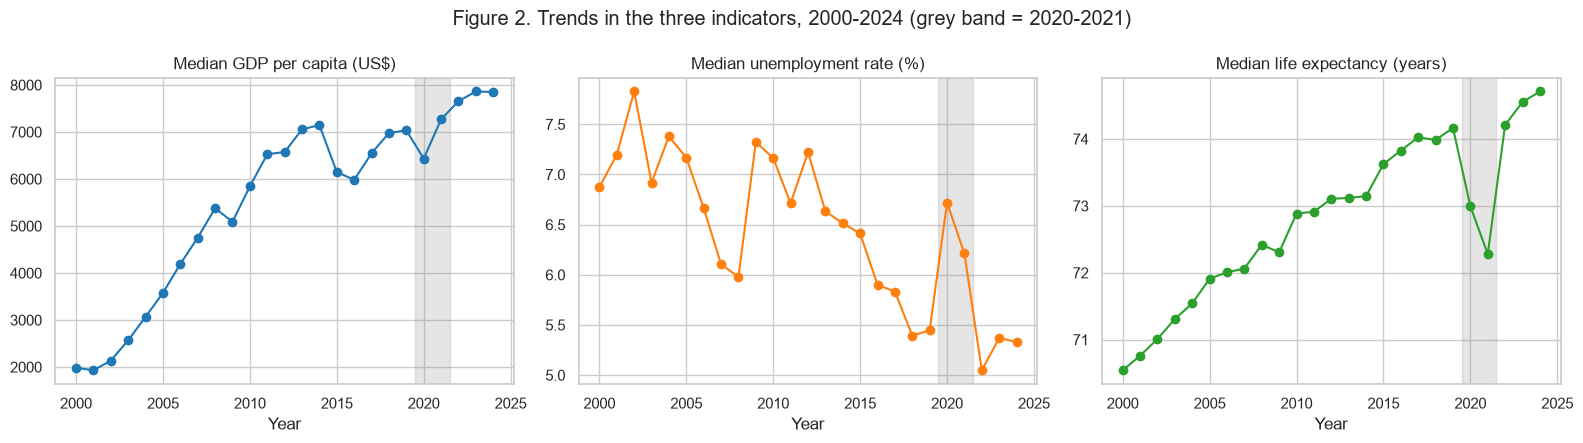

,gdp_per_capita,unemployment_rate,life_expectancy
year,,,
2000,1985.5,6.9,70.5
2010,5843.5,7.2,72.9
2019,7037.0,5.4,74.2
2020,6433.1,6.7,73.0
2021,7268.9,6.2,72.3
2024,7852.4,5.3,74.7


In [13]:
yearly_median = df.groupby("year")[indicators].median()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
titles = [
    "Median GDP per capita (US$)",
    "Median unemployment rate (%)",
    "Median life expectancy (years)",
]
colors = ["tab:blue", "tab:orange", "tab:green"]

for ax, col, title, color in zip(axes, indicators, titles, colors):
    ax.plot(yearly_median.index, yearly_median[col], marker="o", color=color)
    ax.axvspan(2019.5, 2021.5, color="grey", alpha=0.2)  # shade the COVID-19 years
    ax.set_title(title)
    ax.set_xlabel("Year")

fig.suptitle(
    "Figure 2. Trends in the three indicators, 2000-2024 (grey band = 2020-2021)"
)
plt.tight_layout()
plt.savefig("figures/fig2_trends.png", dpi=200, bbox_inches="tight")
plt.show()

yearly_median.loc[[2000, 2010, 2019, 2020, 2021, 2024]].round(1)

**Comparing countries.** Each point below is one country's 2000-2024 average. GDP is on a log scale.

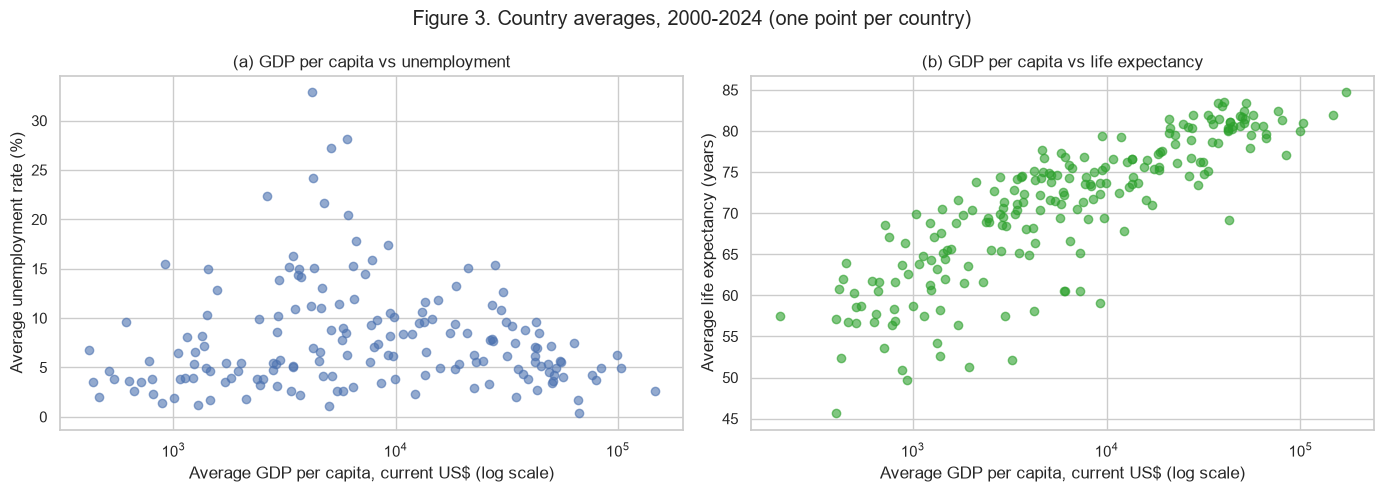

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(
    country_avg["gdp_per_capita"], country_avg["unemployment_rate"], alpha=0.6
)
axes[0].set_xscale("log")
axes[0].set_xlabel("Average GDP per capita, current US$ (log scale)")
axes[0].set_ylabel("Average unemployment rate (%)")
axes[0].set_title("(a) GDP per capita vs unemployment")

axes[1].scatter(
    country_avg["gdp_per_capita"],
    country_avg["life_expectancy"],
    alpha=0.6,
    color="tab:green",
)
axes[1].set_xscale("log")
axes[1].set_xlabel("Average GDP per capita, current US$ (log scale)")
axes[1].set_ylabel("Average life expectancy (years)")
axes[1].set_title("(b) GDP per capita vs life expectancy")

fig.suptitle("Figure 3. Country averages, 2000-2024 (one point per country)")
plt.tight_layout()
plt.savefig("figures/fig3_scatter.png", dpi=200, bbox_inches="tight")
plt.show()

**What the visualisations show**

- **Figure 2:** the median country's life expectancy rose steadily from about 70.5 years in 2000 to 74.7 in 2024, with a clear dip in 2020-2021 (73.0 and 72.3) during COVID-19 before recovering. GDP per capita also rose over the period, with setbacks in crisis years such as 2009 and 2020; because it is in current US dollars, part of the rise is inflation and exchange-rate movement. Unemployment moved within a narrow band and rose in crisis years.
- **Figure 3a:** the points form a cloud with **no clear slope**: knowing a country's income tells you little about its unemployment.
- **Figure 3b:** the points rise clearly from left to right: **richer countries live longer**. The curve flattens at high incomes, so extra income goes with smaller gains once a country is already rich.

### 5d. Missing values and outliers

**Missing values**

In [15]:
missing = pd.DataFrame(
    {
        "missing values": df[indicators].isna().sum(),
        "% missing": (df[indicators].isna().mean() * 100).round(1),
    }
)
missing

,missing values,% missing
gdp_per_capita,183,3.4
unemployment_rate,2248,41.4
life_expectancy,0,0.0


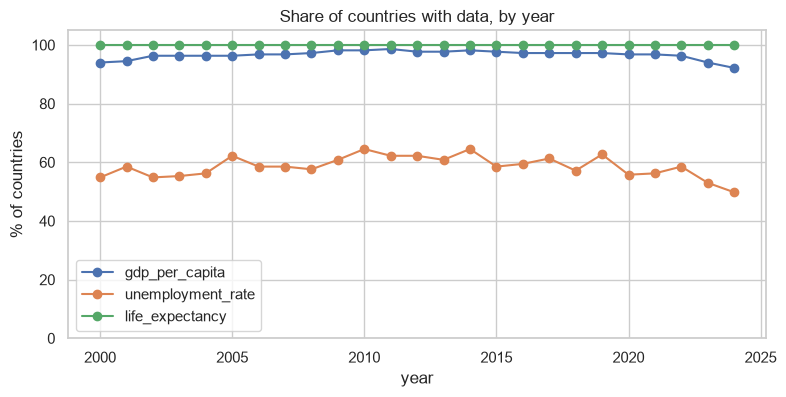

Countries with no unemployment data at all: 10
Countries with fewer than 5 years of unemployment data: 47
Countries with all 25 years: 62

Countries with no GDP data at all: ['British Virgin Islands', 'Gibraltar', "Korea, Dem. People's Rep."]


In [16]:
# Share of countries with data in each year
coverage_by_year = (
    df.groupby("year")[indicators].count() / df["Country Name"].nunique() * 100
)

coverage_by_year.plot(marker="o", figsize=(9, 4))
plt.title("Share of countries with data, by year")
plt.ylabel("% of countries")
plt.ylim(0, 105)
plt.show()

unemp_years = df.groupby("Country Name")["unemployment_rate"].count()
print("Countries with no unemployment data at all:", (unemp_years == 0).sum())
print(
    "Countries with fewer than 5 years of unemployment data:", (unemp_years < 5).sum()
)
print("Countries with all 25 years:", (unemp_years == 25).sum())

gdp_years = df.groupby("Country Name")["gdp_per_capita"].count()
print("\nCountries with no GDP data at all:", list(gdp_years[gdp_years == 0].index))

**What we found and what we did**

- **Life expectancy:** nothing missing.
- **GDP per capita:** about 3% missing, mostly small territories and fragile states (for example the British Virgin Islands, Gibraltar and North Korea have no GDP data; South Sudan, Eritrea and Yemen miss several years).
- **Unemployment:** about 41% missing. Ten countries have no unemployment data at all, and 47 have fewer than 5 years. Coverage is also thinner in the most recent years, because the World Bank had not yet published every country's latest figures.

**Decision:** we **do not fill in** missing values. Making up unemployment figures for countries that never reported them would create patterns that are not in the data. Instead, each analysis uses only the rows where the needed values exist, and country averages need at least 5 years of data (Step 5 in Section 4).

**Outliers**

We use the common **IQR rule**: a value is an outlier if it is more than 1.5 x IQR below the 25th percentile or above the 75th percentile (IQR = the distance between the 25th and 75th percentiles).

In [17]:
def count_outliers(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    low_limit = q1 - 1.5 * iqr
    high_limit = q3 + 1.5 * iqr
    n_low = (series < low_limit).sum()
    n_high = (series > high_limit).sum()
    return round(low_limit, 1), round(high_limit, 1), n_low, n_high


rows = []
for col in indicators:
    low_limit, high_limit, n_low, n_high = count_outliers(df[col].dropna())
    rows.append([col, low_limit, high_limit, n_low, n_high])

pd.DataFrame(
    rows,
    columns=[
        "indicator",
        "lower limit",
        "upper limit",
        "outliers below",
        "outliers above",
    ],
)

,indicator,lower limit,upper limit,outliers below,outliers above
0,gdp_per_capita,-27993.6,50859.6,0,423
1,unemployment_rate,-5.4,19.5,0,185
2,life_expectancy,47.5,95.6,56,0


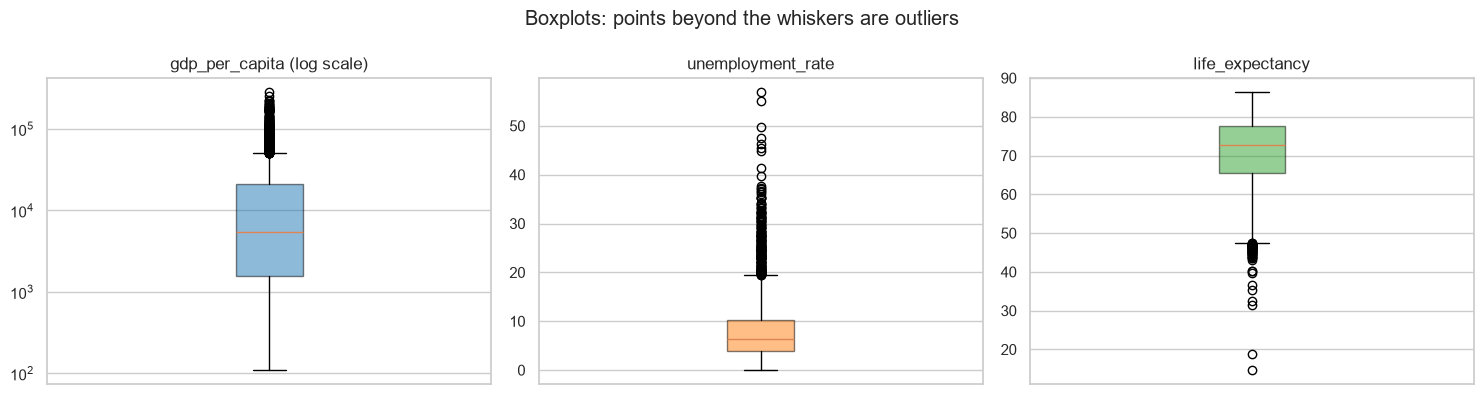

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, color in zip(axes, indicators, colors):
    ax.boxplot(
        df[col].dropna(), patch_artist=True, boxprops=dict(facecolor=color, alpha=0.5)
    )
    ax.set_title(col)
    ax.set_xticks([])
axes[0].set_yscale("log")
axes[0].set_title("gdp_per_capita (log scale)")
plt.suptitle("Boxplots: points beyond the whiskers are outliers")
plt.tight_layout()
plt.show()

In [19]:
print("Highest GDP per capita:")
print(
    df.nlargest(5, "gdp_per_capita")[["Country Name", "year", "gdp_per_capita"]]
    .round(0)
    .to_string(index=False)
)
print("\nHighest unemployment:")
print(
    df.nlargest(5, "unemployment_rate")[
        ["Country Name", "year", "unemployment_rate"]
    ].to_string(index=False)
)
print("\nLowest life expectancy:")
print(
    df.nsmallest(5, "life_expectancy")[["Country Name", "year", "life_expectancy"]]
    .round(1)
    .to_string(index=False)
)

Highest GDP per capita:
 Country Name  year  gdp_per_capita
       Monaco  2024        288002.0
       Monaco  2023        256800.0
       Monaco  2022        226052.0
       Monaco  2021        223823.0
Liechtenstein  2024        220167.0

Highest unemployment:
Country Name  year  unemployment_rate
      Kosovo  2001               57.0
      Kosovo  2002               55.0
      Kosovo  2003               49.7
      Kosovo  2008               47.5
      Kosovo  2007               46.3

Lowest life expectancy:
            Country Name  year  life_expectancy
Central African Republic  2009             14.7
Central African Republic  2022             18.8
Central African Republic  2019             31.5
      Somalia, Fed. Rep.  2011             32.5
             South Sudan  2017             35.4


**What the outlier check shows (outliers are reported, not removed)**

- **GDP per capita:** about 420 country-years (8%) are above the upper limit of roughly \$50,900. They are real, very rich economies such as Monaco, Liechtenstein, Bermuda, Luxembourg, Norway and Switzerland. This is why we use a log scale.
- **Unemployment:** about 185 country-years (6%) are above about 19.5%, mainly Kosovo, North Macedonia, Namibia and South Africa. These look like genuine long-lasting unemployment, not errors.
- **Life expectancy:** 56 country-years (1%) are below about 47.5 years. Most are plausible (Lesotho, Eswatini and Zimbabwe during the HIV/AIDS epidemic). A few look doubtful: the **Central African Republic is recorded at 14.7 years in 2009** and jumps back above 46 the next year. Single-year drops in Haiti (2010 earthquake) and Somalia (2011 famine) are real shocks. We keep all values but treat the Central African Republic with caution.

### 5e. Trends, patterns and relationships

**Comparing two continents: Africa and Europe.** We plot the median life expectancy and median GDP per capita of each continent over time.

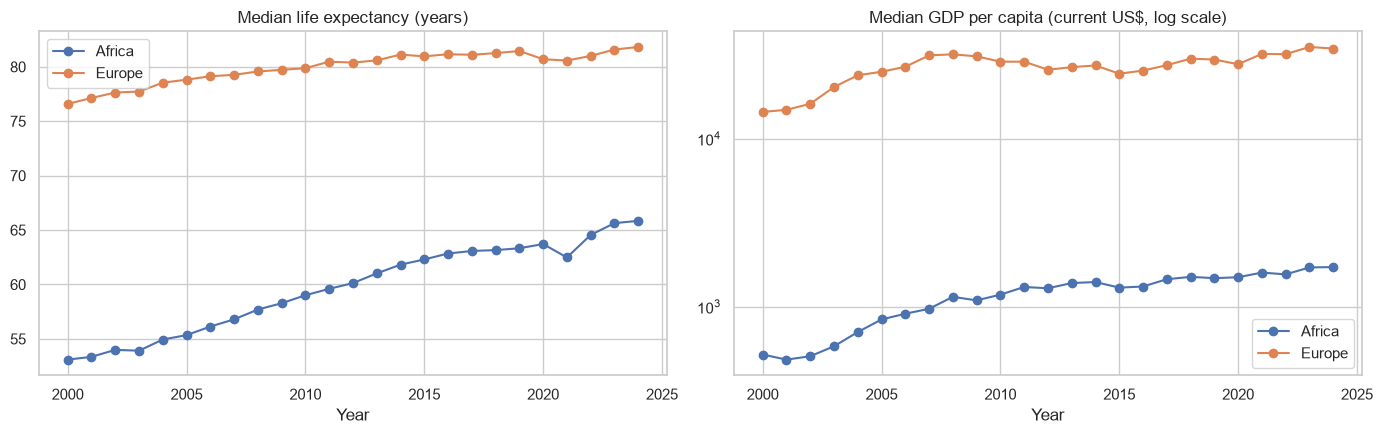

Europe minus Africa, median life expectancy (years):
year
2000    23.5
2010    20.9
2019    18.1
2024    16.0
dtype: float64


In [20]:
continent_year = (
    df.groupby(["year", "continent"])[["life_expectancy", "gdp_per_capita"]]
    .median()
    .reset_index()
)
two = continent_year[continent_year["continent"].isin(["Africa", "Europe"])]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for name, group in two.groupby("continent"):
    axes[0].plot(group["year"], group["life_expectancy"], marker="o", label=name)
    axes[1].plot(group["year"], group["gdp_per_capita"], marker="o", label=name)
axes[0].set_title("Median life expectancy (years)")
axes[1].set_title("Median GDP per capita (current US$, log scale)")
axes[1].set_yscale("log")
for ax in axes:
    ax.set_xlabel("Year")
    ax.legend()
plt.tight_layout()
plt.show()

le = continent_year.pivot(index="year", columns="continent", values="life_expectancy")
gap = le["Europe"] - le["Africa"]
print("Europe minus Africa, median life expectancy (years):")
print(gap.loc[[2000, 2010, 2019, 2024]].round(1))

**What this shows:** Europe stays far ahead on both income and health, but **the life expectancy gap is closing**: it shrank from about 23.5 years in 2000 to 18.1 in 2019 and 16.0 in 2024. Africa gained life expectancy quickly even though its median income stayed low.

**Comparing two countries: Rwanda and South Africa.** Two African countries with very different paths.

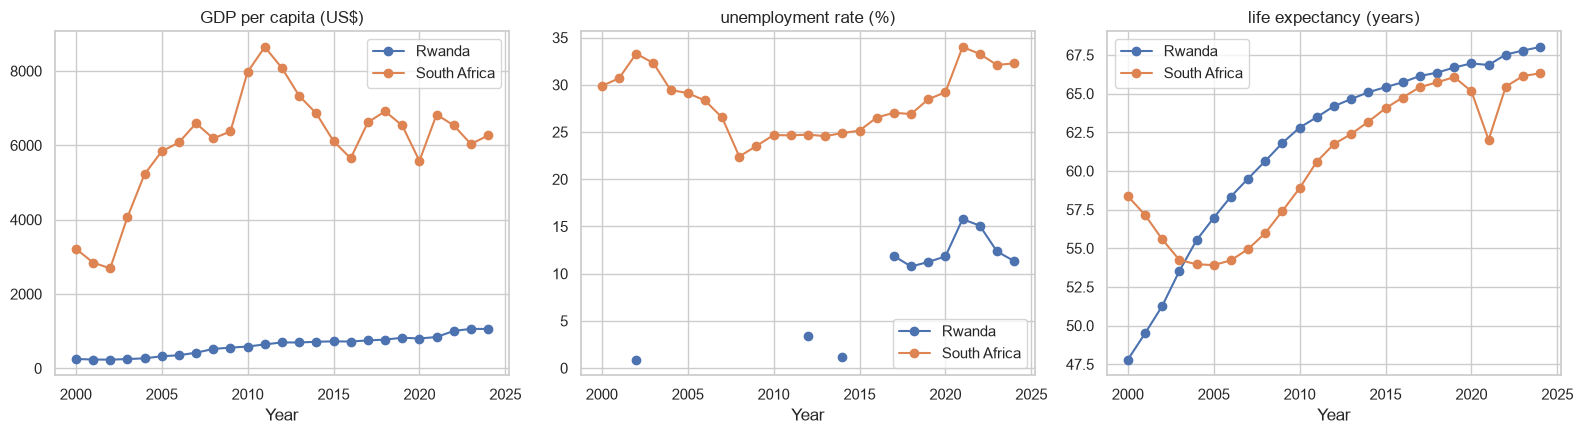

Country Name,Rwanda,South Africa
year,,
2000,47.8,58.4
2005,57.0,53.9
2010,62.8,58.9
2019,66.7,66.1
2021,66.8,62.0
2024,68.0,66.3


In [21]:
pair = df[df["Country Name"].isin(["Rwanda", "South Africa"])]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col, title in zip(axes, indicators, titles):
    for name, group in pair.groupby("Country Name"):
        ax.plot(group["year"], group[col], marker="o", label=name)
    ax.set_title(title.replace("Median ", ""))
    ax.set_xlabel("Year")
    ax.legend()
plt.tight_layout()
plt.show()

pair.pivot(index="year", columns="Country Name", values="life_expectancy").loc[
    [2000, 2005, 2010, 2019, 2021, 2024]
].round(1)

**What this shows:** South Africa is much richer than Rwanda but has far higher unemployment (above 20% in every year). Rwanda's life expectancy climbed steadily from 47.8 to 68.0 years. South Africa's **fell** from 58.4 in 2000 to 53.9 in 2005 (the HIV/AIDS crisis), recovered to 66.1 by 2019, dipped to 62.0 in 2021 (COVID-19) and was back at 66.3 in 2024. By 2024 the two countries had similar life expectancy despite a large income gap, so income is not the whole story.

**Abrupt dips: the COVID-19 years.** How many countries saw life expectancy fall from one year to the next?

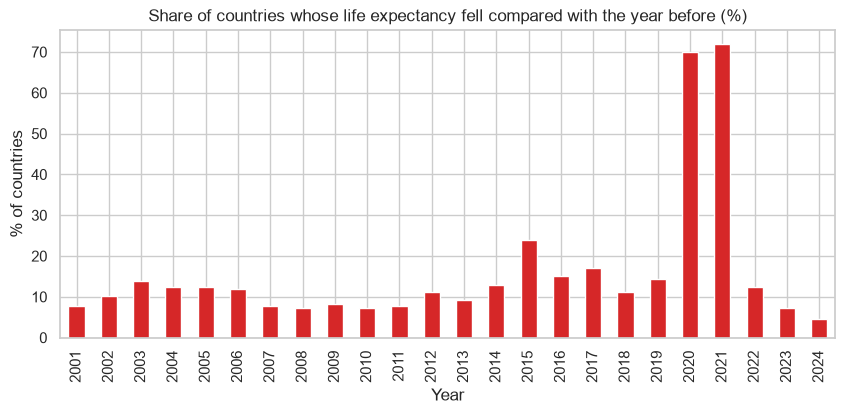

year
2010     7.0
2019    14.0
2020    70.0
2021    72.0
2022    12.0
2024     5.0
Name: le_change, dtype: float64

In [22]:
df = df.sort_values(["Country Name", "year"])
df["le_change"] = df.groupby("Country Name")[
    "life_expectancy"
].diff()  # change from previous year

share_fell = (
    df.dropna(subset=["le_change"])
    .groupby("year")["le_change"]
    .apply(lambda s: (s < 0).mean() * 100)
)

share_fell.plot(kind="bar", figsize=(10, 4), color="tab:red")
plt.title(
    "Share of countries whose life expectancy fell compared with the year before (%)"
)
plt.ylabel("% of countries")
plt.xlabel("Year")
plt.show()

share_fell.loc[[2010, 2019, 2020, 2021, 2022, 2024]].round(0)

**What this shows:** in a normal year fewer than 15% of countries see life expectancy fall. In **2020 about 70% and in 2021 about 72%** of countries went backwards, the clearest abrupt dip in the data. In 2022 most countries bounced back.

### 5f. Answers to the eight questions

**A note on correlation.** We measure how strongly two indicators move together with a **correlation** between -1 and +1. +1 means they always rise together, 0 means no link, and -1 means one rises as the other falls. As a rough guide, about 0.1 is weak, 0.5 moderate and above 0.8 strong.

We use the **Spearman** version (`method="spearman"` in pandas). It compares the *ranks* of countries instead of the raw values, so it is not thrown off by the very skewed GDP figures.

#### Question 1: How are GDP per capita, unemployment and life expectancy related across countries from 2000 to 2024?
*(uses GDP per capita + both supporting indicators)*

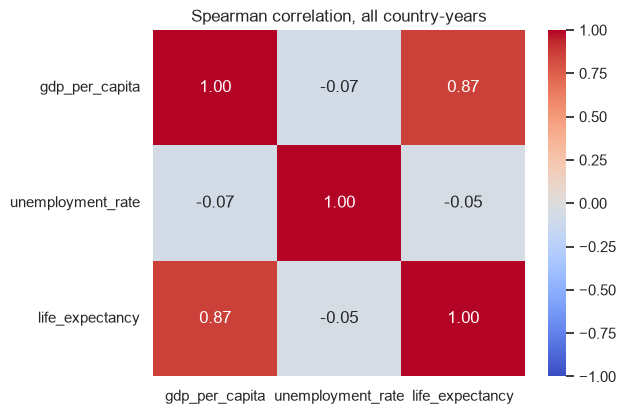

,gdp_per_capita,unemployment_rate,life_expectancy
gdp_per_capita,1.00,-0.07,0.87
unemployment_rate,-0.07,1.00,-0.05
life_expectancy,0.87,-0.05,1.00


In [23]:
corr = df[indicators].corr(method="spearman")

plt.figure(figsize=(6, 4.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Spearman correlation, all country-years")
plt.show()
corr.round(2)

**Answer:** **GDP per capita and life expectancy are strongly linked** (correlation about 0.87): richer countries live longer. **Unemployment is essentially unrelated** to both GDP per capita and life expectancy (correlations close to zero, between -0.1 and +0.1). Unemployment is reported for only about 59% of country-years, so its results rest on fewer countries.

#### Question 2: Do countries with higher GDP per capita tend to have lower unemployment rates?
*(uses GDP per capita + unemployment)*

We split countries into four equal-sized **income groups** (quartiles) by their average GDP per capita and compare unemployment across the groups.

Countries used: 170
Correlation (GDP vs unemployment): 0.05

Median unemployment by income group (%):
income_group
Low             4.6
Lower-middle    8.7
Upper-middle    8.4
High            5.6
Name: unemployment_rate, dtype: float64


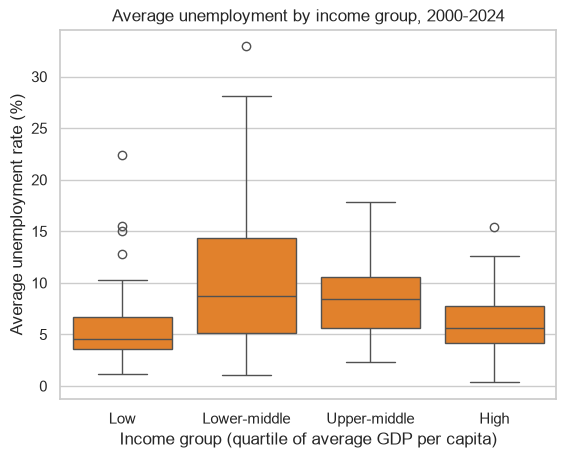

In [24]:
q2 = country_avg.dropna(subset=["gdp_per_capita", "unemployment_rate"]).copy()
q2["income_group"] = pd.qcut(
    q2["gdp_per_capita"], 4, labels=["Low", "Lower-middle", "Upper-middle", "High"]
)

print("Countries used:", len(q2))
print(
    "Correlation (GDP vs unemployment):",
    round(q2["gdp_per_capita"].corr(q2["unemployment_rate"], method="spearman"), 2),
)
print("\nMedian unemployment by income group (%):")
print(q2.groupby("income_group", observed=True)["unemployment_rate"].median().round(1))

sns.boxplot(data=q2, x="income_group", y="unemployment_rate", color="tab:orange")
plt.title("Average unemployment by income group, 2000-2024")
plt.xlabel("Income group (quartile of average GDP per capita)")
plt.ylabel("Average unemployment rate (%)")
plt.show()

**Answer:** **No.** Across about 170 countries the correlation is close to zero (about 0.05). The pattern is a hump, not a slope: median unemployment is lowest in the poorest group (about 4.6%) and the richest group (about 5.6%) and highest in the two middle groups (about 8.5%). A likely reason is that in poor countries most people work informally and cannot afford to stay unemployed, so measured unemployment is low.

#### Question 3: Do countries with higher GDP per capita tend to have longer life expectancy?
*(uses GDP per capita + life expectancy)*

Countries used: 213
Correlation (GDP vs life expectancy): 0.87

Median life expectancy by income group (years):
income_group
Low             61.5
Lower-middle    70.7
Upper-middle    74.2
High            80.6
Name: life_expectancy, dtype: float64


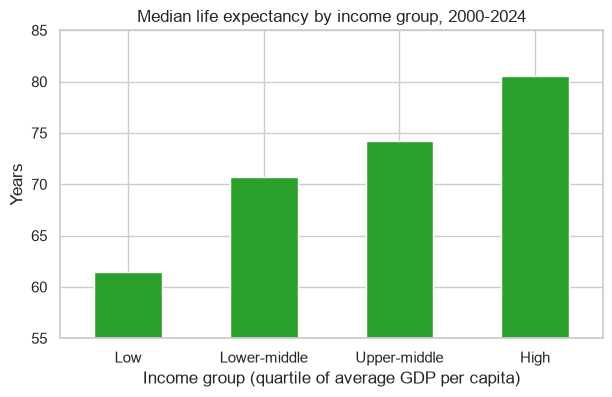

In [37]:
q3 = country_avg.dropna(subset=["gdp_per_capita", "life_expectancy"]).copy()
q3["income_group"] = pd.qcut(
    q3["gdp_per_capita"], 4, labels=["Low", "Lower-middle", "Upper-middle", "High"]
)

print("Countries used:", len(q3))
print(
    "Correlation (GDP vs life expectancy):",
    round(q3["gdp_per_capita"].corr(q3["life_expectancy"], method="spearman"), 2),
)

le_by_group = q3.groupby("income_group", observed=True)["life_expectancy"].median()
print("\nMedian life expectancy by income group (years):")
print(le_by_group.round(1))

le_by_group.plot(kind="bar", color="tab:green", figsize=(7, 4))
plt.title("Median life expectancy by income group, 2000-2024")
plt.xlabel("Income group (quartile of average GDP per capita)")
plt.ylim(55, 85)
plt.ylabel("Years")
plt.xticks(rotation=0)
plt.show()

**Answer:** **Yes, clearly.** Median life expectancy climbs like a staircase: about **61.1 years** in the poorest group, 70.4 in the lower-middle, 74.2 in the upper-middle and **80.5** in the richest. The biggest step (about 9 years) is between the poorest and the next group, so the gains are largest when moving out of the lowest incomes. This is an association: health can also raise income, and both depend on things like good public services.

#### Question 7: Which countries have high GDP per capita but also high unemployment?
*(uses GDP per capita + unemployment + life expectancy)*

"High" means in the **top 25%** (top quartile) of country averages for that indicator.

In [26]:
q7 = country_avg.dropna(subset=["gdp_per_capita", "unemployment_rate"]).copy()

gdp_cut = q7["gdp_per_capita"].quantile(0.75)
unemp_cut = q7["unemployment_rate"].quantile(0.75)
print(f"High GDP per capita: at least ${gdp_cut:,.0f}")
print(f"High unemployment: above {unemp_cut:.1f}%")

high_gdp = q7[q7["gdp_per_capita"] >= gdp_cut]
both = high_gdp[high_gdp["unemployment_rate"] > unemp_cut]
print(
    f"\n{len(both)} of the {len(high_gdp)} high-GDP countries also have high unemployment:"
)
both[
    ["Country Name", "gdp_per_capita", "unemployment_rate", "life_expectancy"]
].sort_values("unemployment_rate", ascending=False).round(1)

High GDP per capita: at least $26,452
High unemployment: above 9.9%

4 of the 43 high-GDP countries also have high unemployment:


,Country Name,gdp_per_capita,unemployment_rate,life_expectancy
179,Spain,27905.4,15.4,81.9
140,New Caledonia,30465.1,12.6,76.3
158,Puerto Rico (US),27149.1,11.3,78.9
13,"Bahamas, The",29739.9,10.9,73.4


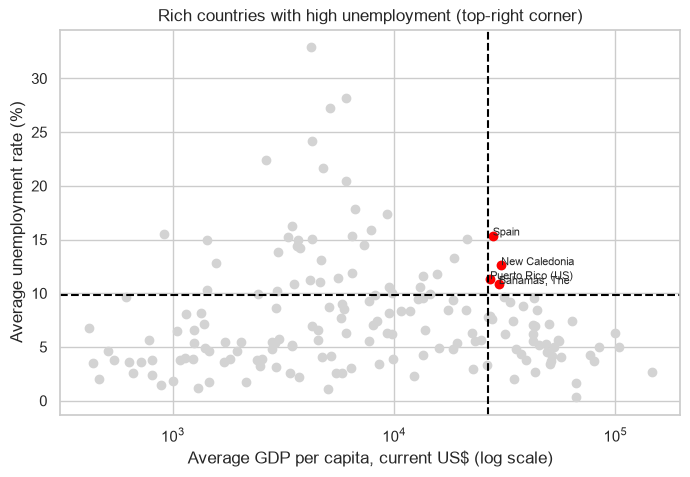

In [27]:
plt.figure(figsize=(8, 5))
plt.scatter(q7["gdp_per_capita"], q7["unemployment_rate"], color="lightgrey")
plt.scatter(both["gdp_per_capita"], both["unemployment_rate"], color="red")
for _, row in both.iterrows():
    plt.annotate(
        row["Country Name"],
        (row["gdp_per_capita"], row["unemployment_rate"]),
        fontsize=8,
    )
plt.axvline(gdp_cut, color="black", linestyle="--")
plt.axhline(unemp_cut, color="black", linestyle="--")
plt.xscale("log")
plt.xlabel("Average GDP per capita, current US$ (log scale)")
plt.ylabel("Average unemployment rate (%)")
plt.title("Rich countries with high unemployment (top-right corner)")
plt.show()

**Answer:** **Very few.** Only about 4 of the 43 high-GDP countries (at least about \$26,500 per person) also have high unemployment (above about 9.9%): **Spain** (15.4%), New Caledonia (12.6%), Puerto Rico (11.3%) and The Bahamas (10.9%). Spain is the only large economy on the list, and its life expectancy is high (81.9 years), so high unemployment does not come with poor health there. Italy (9.2%) and France (8.8%) sit just below the cut-off, so the list depends on where the line is drawn.

#### Question 8: Which countries have low GDP per capita but relatively high life expectancy?
*(uses GDP per capita + life expectancy)*

"Low GDP" means the **bottom 25%** of countries. To judge "relatively high" life expectancy we draw a straight trend line through all countries (life expectancy against log GDP) and see which poor countries sit furthest **above** it, that is, live longer than their income would suggest.

In [28]:
q8 = country_avg.dropna(subset=["gdp_per_capita", "life_expectancy"]).copy()
q8["log_gdp"] = np.log10(q8["gdp_per_capita"])

# Straight trend line: life_expectancy = slope * log_gdp + intercept
slope, intercept = np.polyfit(q8["log_gdp"], q8["life_expectancy"], 1)
q8["expected_le"] = slope * q8["log_gdp"] + intercept
q8["years_above_trend"] = q8["life_expectancy"] - q8["expected_le"]

low_cut = q8["gdp_per_capita"].quantile(0.25)
median_le = q8["life_expectancy"].median()
low_gdp = q8[q8["gdp_per_capita"] <= low_cut]

print(f"Low GDP per capita: at most ${low_cut:,.0f} ({len(low_gdp)} countries)")
print(f"Median life expectancy of all countries: {median_le:.1f} years")
print(
    "Low-GDP countries above that median:",
    (low_gdp["life_expectancy"] > median_le).sum(),
)

low_gdp.sort_values("years_above_trend", ascending=False)[
    ["Country Name", "gdp_per_capita", "life_expectancy", "years_above_trend"]
].head(8).round(1)

Low GDP per capita: at most $1,813 (54 countries)
Median life expectancy of all countries: 72.4 years
Low-GDP countries above that median: 0


,Country Name,gdp_per_capita,life_expectancy,years_above_trend
190,Tajikistan,715.6,68.5,7.7
107,Kyrgyz Republic,1044.3,69.9,7.4
142,Nicaragua,1720.0,71.6,6.6
189,Syrian Arab Republic,1422.0,70.5,6.4
138,Nepal,751.6,67.1,6.0
15,Bangladesh,1229.9,68.8,5.4
61,Eritrea,451.9,63.9,5.3
208,Uzbekistan,1812.9,69.8,4.6


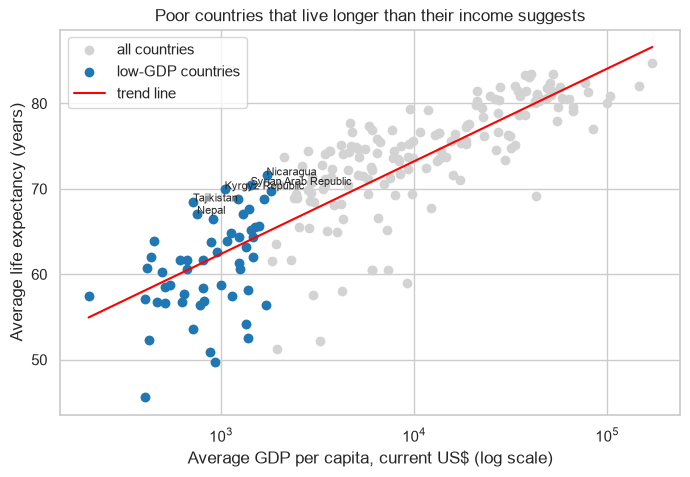

In [29]:
plt.figure(figsize=(8, 5))
plt.scatter(
    q8["gdp_per_capita"],
    q8["life_expectancy"],
    color="lightgrey",
    label="all countries",
)
plt.scatter(
    low_gdp["gdp_per_capita"],
    low_gdp["life_expectancy"],
    color="tab:blue",
    label="low-GDP countries",
)
xs = np.linspace(q8["log_gdp"].min(), q8["log_gdp"].max(), 100)
plt.plot(10**xs, slope * xs + intercept, color="red", label="trend line")
for _, row in low_gdp.nlargest(5, "years_above_trend").iterrows():
    plt.annotate(
        row["Country Name"], (row["gdp_per_capita"], row["life_expectancy"]), fontsize=8
    )
plt.xscale("log")
plt.xlabel("Average GDP per capita, current US$ (log scale)")
plt.ylabel("Average life expectancy (years)")
plt.title("Poor countries that live longer than their income suggests")
plt.legend()
plt.show()

**Answer:** **No poor country beats the world median** life expectancy (about 72.4 years), so income still sets a ceiling. But several live much longer than their income predicts. **Tajikistan** (68.5 years on about \$716 per person, about 7.8 years above the trend), the **Kyrgyz Republic** (+7.4), **Nicaragua** (+6.7), **Syria** (+6.4), **Nepal** (+6.1) and **Bangladesh** (+5.5) stand out, many of them in Central and South Asia. Why they do better is not tested here.

#### Question 9: Did these relationships differ between 2000-2019 and 2020-2024?
*(uses GDP per capita + both supporting indicators)*

In [30]:
before = df[df["year"] <= 2019]
after = df[df["year"] >= 2020]

pairs = [
    ("gdp_per_capita", "life_expectancy"),
    ("gdp_per_capita", "unemployment_rate"),
    ("unemployment_rate", "life_expectancy"),
]

rows = []
for x, y in pairs:
    rows.append(
        [
            f"{x} vs {y}",
            round(before[x].corr(before[y], method="spearman"), 2),
            round(after[x].corr(after[y], method="spearman"), 2),
        ]
    )

pd.DataFrame(rows, columns=["pair", "2000-2019", "2020-2024"])

,pair,2000-2019,2020-2024
0,gdp_per_capita vs life_expectancy,0.87,0.86
1,gdp_per_capita vs unemployment_rate,-0.05,-0.10
2,unemployment_rate vs life_expectancy,-0.04,-0.05


In [31]:
print("Average yearly change in life expectancy (years):")
print("  2000-2019:", round(before["le_change"].mean(), 2))
print("  2020-2024:", round(after["le_change"].mean(), 2))

Average yearly change in life expectancy (years):
  2000-2019: 0.29
  2020-2024: 0.2


**Answer:** **Hardly at all.** The link between GDP per capita and life expectancy stayed strong through the pandemic (about 0.87 before 2020 and 0.86 after). Unemployment stayed close to unrelated to both (about -0.05 and -0.10 with GDP; -0.04 and -0.05 with life expectancy). What did change is the **pace of progress**: life expectancy rose by about 0.29 years per year before 2020 but only about 0.20 per year in 2020-2024. Note that 2020-2024 is only five years of data.

#### Question 10: How do the three indicators differ across continents?

In [32]:
continent_order = [
    "Africa",
    "Asia",
    "Europe",
    "North America",
    "South America",
    "Oceania",
]

summary = (
    country_avg.groupby("continent")
    .agg(
        countries=("Country Name", "count"),
        median_gdp=("gdp_per_capita", "median"),
        median_life_exp=("life_expectancy", "median"),
        median_unemployment=("unemployment_rate", "median"),
    )
    .reindex(continent_order)
)
summary.round(1)

,countries,median_gdp,median_life_exp,median_unemployment
continent,,,,
Africa,54,1245.2,59.7,6.6
Asia,49,3798.2,72.7,4.4
Europe,49,26102.6,80.0,7.1
North America,34,13316.8,74.5,7.8
South America,12,5862.2,73.7,8.4
Oceania,19,4257.0,69.9,6.1


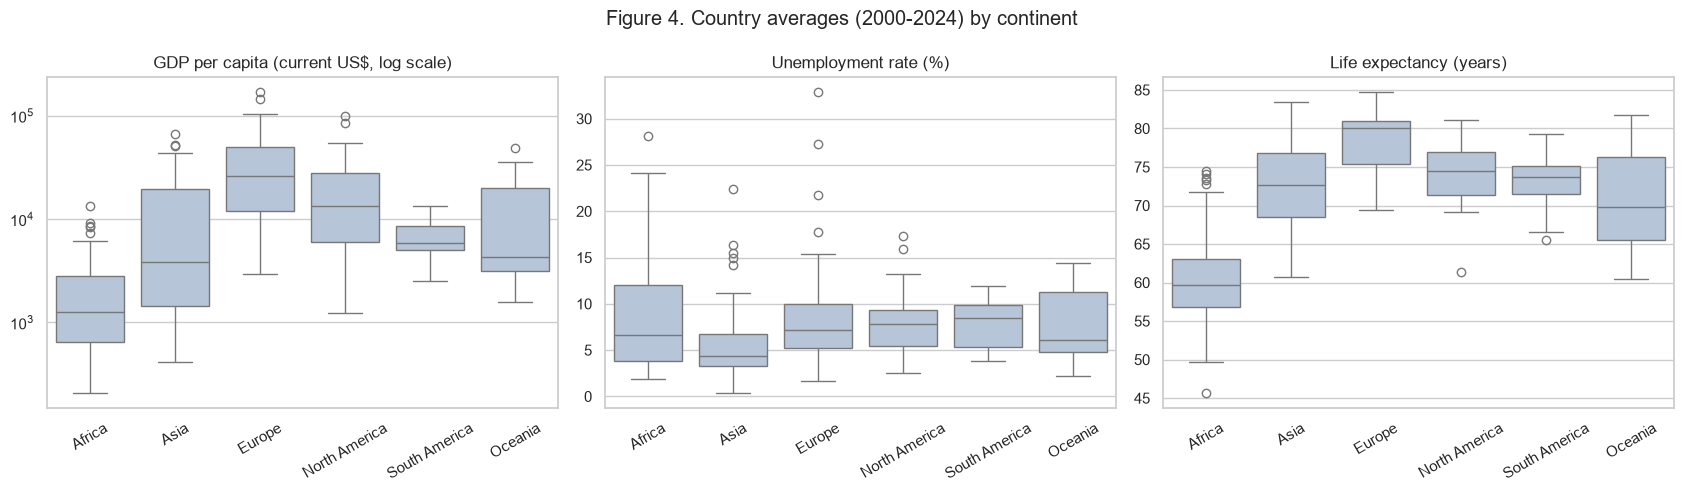

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
plot_titles = [
    "GDP per capita (current US$, log scale)",
    "Unemployment rate (%)",
    "Life expectancy (years)",
]

for ax, col, title in zip(axes, indicators, plot_titles):
    sns.boxplot(
        data=country_avg,
        x="continent",
        y=col,
        order=continent_order,
        ax=ax,
        color="lightsteelblue",
    )
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(axis="x", rotation=30)
axes[0].set_yscale("log")

fig.suptitle("Figure 4. Country averages (2000-2024) by continent")
plt.tight_layout()
plt.savefig("figures/fig4_continents.png", dpi=200, bbox_inches="tight")
plt.show()

**Answer:** Continents differ **hugely in income and health** but **only a little in unemployment**.

- **GDP per capita (median):** Europe is highest (about \$26,100), then North America (\$13,300), South America (\$5,900), Oceania (\$4,300), Asia (\$3,800) and Africa lowest (about \$1,200), roughly a 20-fold gap.
- **Life expectancy (median):** Europe 80.0 years, North America 74.5, South America 73.7, Asia 72.7, Oceania 69.9 and Africa 59.7, about a 20-year gap.
- **Unemployment (median):** from 4.4% (Asia) to 8.4% (South America). It does **not** follow income: Africa, the poorest, sits in the middle (6.6%) and Europe is at 7.1%.
- Oceania is richer than Asia but has lower life expectancy, another sign that income is not the whole story.

#### Question 12: Which continent saw the largest life expectancy gain, and how did GDP per capita change over the same period?
*(uses GDP per capita + life expectancy)*

For each country we compare its first and last year of data. To keep the comparison fair we only keep countries whose GDP data start by 2003 and run to at least 2021. Then we take the **median country** in each continent.

In [34]:
gdp_rows = df.dropna(subset=["gdp_per_capita"]).sort_values(["Country Name", "year"])

change = (
    gdp_rows.groupby(["Country Name", "continent"])
    .agg(
        first_year=("year", "first"),
        last_year=("year", "last"),
        gdp_start=("gdp_per_capita", "first"),
        gdp_end=("gdp_per_capita", "last"),
    )
    .reset_index()
)

# Life expectancy has no gaps, so its first and last years are 2000 and 2024
le_2000 = df[df["year"] == 2000].set_index("Country Name")["life_expectancy"]
le_2024 = df[df["year"] == 2024].set_index("Country Name")["life_expectancy"]
change["le_start"] = change["Country Name"].map(le_2000)
change["le_end"] = change["Country Name"].map(le_2024)

change = change[(change["first_year"] <= 2003) & (change["last_year"] >= 2021)]
change["le_gain"] = change["le_end"] - change["le_start"]
change["gdp_multiple"] = (
    change["gdp_end"] / change["gdp_start"]
)  # 2.0 = GDP per capita doubled

print("Countries kept:", len(change))
result = (
    change.groupby("continent")
    .agg(
        countries=("Country Name", "count"),
        le_start=("le_start", "median"),
        le_end=("le_end", "median"),
        median_le_gain=("le_gain", "median"),
        median_gdp_multiple=("gdp_multiple", "median"),
    )
    .reindex(continent_order)
)
result.sort_values("median_le_gain", ascending=False).round(1)

Countries kept: 206


,countries,le_start,le_end,median_le_gain,median_gdp_multiple
continent,,,,,
Africa,52,53.1,65.8,9.8,2.9
Asia,47,70.9,74.9,6.5,3.8
South America,12,70.5,76.8,5.9,3.5
Europe,47,76.6,81.8,4.7,3.4
North America,29,72.5,75.1,3.7,2.4
Oceania,19,68.6,71.7,3.4,2.9


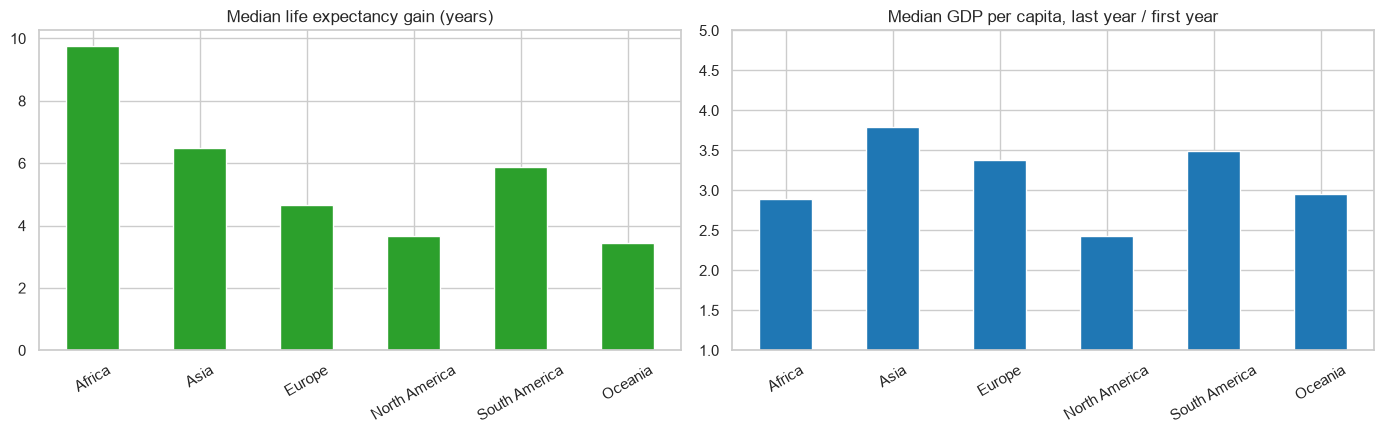

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
result["median_le_gain"].plot(kind="bar", ax=axes[0], color="tab:green")
axes[0].set_title("Median life expectancy gain (years)")
result["median_gdp_multiple"].plot(kind="bar", ax=axes[1], color="tab:blue")
axes[1].set_title("Median GDP per capita, last year / first year")
axes[1].set_ylim(1.0, 5)
for ax in axes:
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

**Answer:** **Africa** gained the most: the median African country went from 53.1 to 65.8 years, a gain of **about 9.8 years**, well ahead of Asia (6.5), South America (5.9), Europe (4.7), North America (3.7) and Oceania (3.4).

GDP per capita rose on every continent, but Africa's growth was **middling** (about 2.9 times, from roughly \$520 to \$1,720), slower than Asia (3.8 times, the fastest), South America (3.5) and Europe (3.4). So the largest health gains did not come with the fastest income growth. They mostly went to where life expectancy started lowest, which looks like catching up on basic health improvements. This reading is not tested here.

## 6. Summary and limitations

**Main findings**

1. **Income and health go together.** Richer countries live much longer (correlation about 0.87), with the biggest gains when moving out of the lowest incomes. The link held in every period, including the COVID-19 years.
2. **Unemployment is the odd one out.** It is not related to GDP per capita or life expectancy across countries. The poorest and richest countries both report low unemployment.
3. **Exceptions are informative.** Spain is a rich country with high unemployment; Tajikistan, the Kyrgyz Republic and Nepal live much longer than their income predicts.
4. **Continents differ greatly** in income (about 20-fold) and life expectancy (about 20 years), but much less in unemployment.
5. **Africa made the largest health gains** (about 9.8 years), even though its GDP per capita did not grow the fastest. The Europe-Africa life expectancy gap narrowed from about 23.5 to 16 years.
6. **COVID-19 caused an abrupt dip:** about 70% of countries saw life expectancy fall in 2020 and 2021, followed by a rebound.

**Limitations**

- GDP per capita is in **current US dollars**, so it mixes real growth with inflation and exchange-rate changes and ignores differences in local prices.
- **Unemployment covers only about 59% of country-years** and uses each country's own definition. In poor countries it misses informal work.
- The continent grouping was made by us from country codes.
- A few values look unreliable (for example the Central African Republic's life expectancy in 2009).
- This is exploratory analysis: all findings are **associations, not causes**.